# P2: repeated width comparison

Three datasets × two widths × three predeclared training seeds (42, 123, 2026). All runs share the original fixed data split. The six seed-42 runs were observed before the twelve new runs were started; all eighteen are included. This notebook reports **selected validation results**, not local-test or hidden-set results.

Mean ± sample SD describes training-seed variability on the fixed split. It is neither a confidence interval nor evidence for generalization across data splits. Width differences are paired by seed for descriptive comparison only; no significance test is claimed with three seeds.

Rebuild the tables with `.venv/bin/python -m member_c.summarize_multiseed`. Configurations, commands, logs, source snapshots and individual predictions are recorded under the declared run IDs in `member_c/configs/p2_multiseed/manifest.json`.

**Display:** Run all cells to plot directly below the code with `plt.show()`. No PDF or image files are exported. Matplotlib renders mathematical labels without external LaTeX.


In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'common.py').is_file())
assert Path(sys.prefix).resolve() == (root/'.venv').resolve()
if str(root) not in sys.path: sys.path.insert(0, str(root))
from member_c.summarize_round1 import collect
from member_c.summarize_multiseed import aggregate, SEEDS
manifest=json.loads((root/'member_c/configs/p2_multiseed/manifest.json').read_text())
rows=collect(manifest)
groups, paired, candidates=aggregate(rows)
header='| Dataset | Width | Seed 42 | Seed 123 | Seed 2026 | Mean ± sample SD |\n|---|---|---:|---:|---:|---:|'
lines=[f"| {r['dataset']} | {r['hidden_sizes']} | {r['accuracy_seed_42']:.2%} | {r['accuracy_seed_123']:.2%} | {r['accuracy_seed_2026']:.2%} | {100*r['mean_validation_accuracy']:.2f} ± {100*r['sample_std_validation_accuracy']:.2f}% |" for r in groups]
display(Markdown(header+'\n'+'\n'.join(lines)))


Matplotlib is building the font cache; this may take a moment.


| Dataset | Width | Seed 42 | Seed 123 | Seed 2026 | Mean ± sample SD |
|---|---|---:|---:|---:|---:|
| 20 | 128x128 | 89.58% | 90.50% | 91.00% | 90.36 ± 0.72% |
| 20 | 256x256 | 91.38% | 89.21% | 91.12% | 90.57 ± 1.19% |
| 30 | 128x128 | 90.83% | 91.25% | 86.83% | 89.63 ± 2.44% |
| 30 | 256x256 | 91.27% | 91.90% | 89.90% | 91.03 ± 1.02% |
| 40 | 128x128 | 93.56% | 92.53% | 93.16% | 93.08 ± 0.52% |
| 40 | 256x256 | 93.19% | 93.23% | 94.05% | 93.49 ± 0.48% |

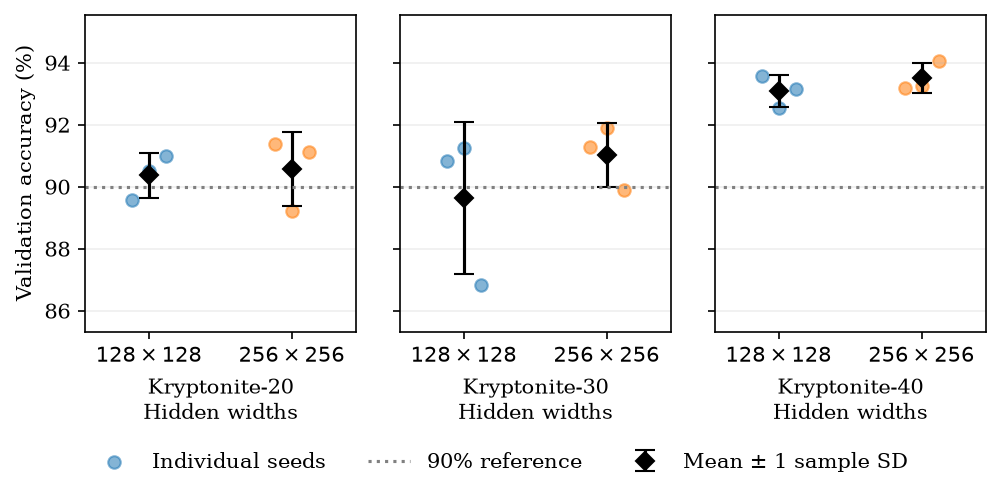

In [2]:
# Plot directly in the notebook; no file export or external LaTeX required.
plt.rcParams.update({
    'text.usetex': False, 'font.family': 'serif', 'font.serif': ['DejaVu Serif'],
    'font.size': 10.1, 'axes.labelsize': 10.1, 'xtick.labelsize': 10.1,
    'ytick.labelsize': 10.1, 'legend.fontsize': 10.1, 'figure.titlesize': 10.1,
    'axes.unicode_minus': True, 'figure.dpi': 150,
})
fig, axes=plt.subplots(1,3,figsize=(6.75,3.25),sharey=True,constrained_layout=False)
all_scores=[100*r['validation_accuracy'] for r in rows]
for ax,dataset in zip(axes,['20','30','40']):
    for i,width in enumerate(['128x128','256x256']):
        g=next(g for g in groups if g['dataset']==dataset and g['hidden_sizes']==width)
        color=['tab:blue','tab:orange'][i]
        ax.scatter(np.array([i-0.12,i,i+0.12]),[100*g[f'accuracy_seed_{s}'] for s in SEEDS],color=color,alpha=0.55,label='Individual seeds' if i==0 else None)
        ax.errorbar(i,100*g['mean_validation_accuracy'],yerr=100*g['sample_std_validation_accuracy'],fmt='D',color='black',capsize=5,label=r'Mean $\pm$ 1 sample SD' if i==0 else None)
    ax.axhline(90,color='0.5',linestyle=':',label=r'90% reference')
    ax.set_xticks([0,1],[r'$128\times128$',r'$256\times256$'])
    ax.set_xlabel(f'Kryptonite-{dataset}'+ '\nHidden widths')
    ax.set_xlim(-0.45,1.45)
    ax.grid(axis='y',alpha=0.2)
axes[0].set_ylabel(r'Validation accuracy (%)')
axes[0].set_ylim(min(all_scores)-1.5,max(all_scores)+1.5)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, frameon=False)
fig.subplots_adjust(left=0.10, right=0.99, top=0.97, bottom=0.32, wspace=0.16)
plt.show()


**Figure.** Validation accuracy at the selected checkpoint of each run. Colored points show the three individual seeds; black diamonds and error bars show their mean and sample standard deviation (ddof=1). Depth, preprocessing, optimizer, learning rate, batch size, maximum epochs and stopping policy are fixed. Actual training epochs and compute differ under early stopping. The 90% reference does not imply hidden-set success. Candidates selected by these means are development candidates, not final test/hidden models.


In [3]:
header='| Dataset | Wide − narrow, seed 42 (pp) | Seed 123 (pp) | Seed 2026 (pp) | Mean difference (pp) |\n|---|---:|---:|---:|---:|'
lines=[f"| {r['dataset']} | {r['difference_seed_42_pp']:+.3f} | {r['difference_seed_123_pp']:+.3f} | {r['difference_seed_2026_pp']:+.3f} | {r['mean_difference_pp']:+.3f} |" for r in paired]
display(Markdown(header+'\n'+'\n'.join(lines)))


| Dataset | Wide − narrow, seed 42 (pp) | Seed 123 (pp) | Seed 2026 (pp) | Mean difference (pp) |
|---|---:|---:|---:|---:|
| 20 | +1.792 | -1.292 | +0.125 | +0.208 |
| 30 | +0.450 | +0.650 | +3.075 | +1.392 |
| 40 | -0.375 | +0.703 | +0.891 | +0.406 |